<a href="https://colab.research.google.com/github/Jionary/Repository-IA/blob/main/03_PED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Estacionariedad de los niveles de Ozono (O3) - Estación PED (2026)

En este notebook realizaremos un análisis de series de tiempo para evaluar si la serie de tiempo de niveles de ozono (O3) en la estación de monitoreo **Pedregal (PED)** durante el año 2026 es de naturaleza estacionaria.

Pasos del análisis en un estilo de programación secuencial y procedimental:
1. Descarga y carga de datos usando el bypass de seguridad SSL.
2. Filtrado y reindexación horaria de la estación PED.
3. Tratamiento de datos faltantes (interpolación lineal y perfil estacional de soporte).
4. Transformaciones para remover estacionalidad diaria y anual.
5. Pruebas formales de raíz unitaria (ADF y KPSS).
6. Visualización de los correlogramas de autocorrelación (ACF) resultantes.

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ssl
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.stattools import acf

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

### 1. Carga y preparación de los datos

Definimos la URL del dataset de la CDMX y leemos los datos directamente usando pandas, manejando el problema de certificados SSL antiguos.

In [75]:
import os
import ssl
import urllib.request

URL = "https://aire.cdmx.gob.mx/descargas/Opendata/anuales_horarios_gz/contaminantes_2026.csv.gz"
ARCHIVO = "contaminantes_2026.csv.gz"

# Limpiamos descargas previas para asegurar una descarga limpia
if os.path.exists(ARCHIVO):
    os.remove(ARCHIVO)

# Descargamos el archivo con el contexto de seguridad compatible
ctx = ssl.create_default_context()
ctx.set_ciphers("DEFAULT@SECLEVEL=1")
with urllib.request.urlopen(URL, context=ctx) as resp, open(ARCHIVO, "wb") as f:
    f.write(resp.read())

# Usamos compresión 'zip' ya que internamente el servidor lo empaqueta con formato PK-ZIP
datos_raw = pd.read_csv(ARCHIVO, compression="zip", skiprows=9)
datos_raw.head()

,date,id_station,id_parameter,valor,unit
0,2026-01-01 00:00:00,ACO,CO,NaN,15
1,2026-01-01 00:00:00,ACO,NO,NaN,1
2,2026-01-01 00:00:00,ACO,NO2,NaN,1
3,2026-01-01 00:00:00,ACO,NOX,NaN,1
4,2026-01-01 00:00:00,ACO,O3,NaN,1


Filtramos para el contaminante O3 y la estación UIZ, y aseguramos un índice de tiempo completo hora por hora.

In [76]:
# Normalizar nombres de columnas del archivo descargado a español
datos_raw = datos_raw.rename(columns={
    'date': 'fecha',
    'id_station': 'id_estacion',
    'id_parameter': 'id_parametro'
})

# Convertir fecha a datetime
datos_raw['fecha'] = pd.to_datetime(datos_raw['fecha'])

# Filtrar O3 para la estación PED (Pedregal)
estacion_objetivo = 'PED'
df_ped = datos_raw[(datos_raw['id_parametro'] == 'O3') & (datos_raw['id_estacion'] == estacion_objetivo)].copy()
df_ped = df_ped.set_index('fecha')

# Reindexar para completar todas las horas del año y detectar faltantes
rango_completo = pd.date_range(start=df_ped.index.min(), end=df_ped.index.max(), freq='h')
df_ped = df_ped.reindex(rango_completo)

# Crear el DataFrame de trabajo principal requerido por las celdas siguientes
serie_ozono = pd.DataFrame(index=df_ped.index)
serie_ozono['original'] = df_ped['valor']
print(f"Análisis de Ozono para la estación: {estacion_objetivo}")
print("Cantidad de valores nulos iniciales:", serie_ozono['original'].isna().sum())

Análisis de Ozono para la estación: PED
Cantidad de valores nulos iniciales: 345


### 2. Imputación de valores faltantes

Para limpiar la serie:
* Si falta una racha corta de tiempo (menor o igual a 6 horas), usamos interpolación lineal.
* Si faltan bloques más grandes, los rellenamos con el promedio histórico para ese mismo mes y hora del día.

In [77]:
temp_serie = serie_ozono['original'].copy()

# Identificar bloques de NaN menores o iguales a 6 horas
is_na = temp_serie.isna()
longitudes_nan = is_na.groupby((~is_na).cumsum()).transform('sum')

# 1. Aplicamos interpolación lineal para faltantes cortos (<= 6 horas)
serie_interpolada = temp_serie.interpolate(method='linear', limit=6)

# 2. Para los bloques grandes de NaN, calculamos el perfil promedio histórico por mes y hora
serie_ozono['mes'] = serie_ozono.index.month
serie_ozono['hora'] = serie_ozono.index.hour
promedio_perfil = serie_ozono.groupby(['mes', 'hora'])['original'].transform('mean')

# Rellenamos los remanentes usando el perfil de mes y hora
serie_ozono['limpia'] = serie_interpolada.fillna(promedio_perfil)

# Eliminamos las columnas auxiliares creadas temporalmente
serie_ozono.drop(columns=['mes', 'hora'], inplace=True)

print("Nulos remanentes en la serie limpia de la estación PED:", serie_ozono['limpia'].isna().sum())

Nulos remanentes en la serie limpia de la estación PED: 0


### 3. Aplicación de transformaciones para remover estacionalidad

In [78]:
# 1. Remover perfil diario promedio (estacionalidad diaria simple)
perfil_diario = serie_ozono.groupby(serie_ozono.index.hour)['limpia'].transform('mean')
serie_ozono['sin_perfil_diario'] = serie_ozono['limpia'] - perfil_diario

# 2. Remover perfil mensual-horario (estacionalidad detallada por mes y hora)
serie_ozono['mes'] = serie_ozono.index.month
serie_ozono['hora'] = serie_ozono.index.hour
perfil_mes_hora = serie_ozono.groupby(['mes', 'hora'])['limpia'].transform('mean')
serie_ozono['sin_perfil_mes_hora'] = serie_ozono['limpia'] - perfil_mes_hora
serie_ozono.drop(columns=['mes', 'hora'], inplace=True)

# 3. Diferencia estacional de 24 horas
serie_ozono['dif_estacional_24h'] = serie_ozono['limpia'].diff(24)

# Mostrar vista previa de las transformaciones exitosas
serie_ozono[['limpia', 'sin_perfil_diario', 'sin_perfil_mes_hora', 'dif_estacional_24h']].head(10)

,limpia,sin_perfil_diario,sin_perfil_mes_hora,dif_estacional_24h
2026-01-01 00:00:00,4.0,-15.863965,-13.293548,NaN
2026-01-01 01:00:00,12.0,-8.193328,-6.238710,NaN
2026-01-01 02:00:00,15.0,-5.201405,-3.377419,NaN
2026-01-01 03:00:00,18.0,-1.341207,0.322581,NaN
2026-01-01 04:00:00,20.0,2.371365,4.483871,NaN
2026-01-01 05:00:00,13.0,-1.320747,0.677419,NaN
2026-01-01 06:00:00,3.0,-5.862823,-4.161290,NaN
2026-01-01 07:00:00,4.0,-5.162137,-0.387097,NaN
2026-01-01 08:00:00,10.0,-5.887083,3.193548,NaN
2026-01-01 09:00:00,30.0,2.421271,14.612903,NaN


### 4. Pruebas de Estacionariedad

Definimos una función simple para ejecutar las pruebas ADF y KPSS sobre nuestras series.

In [79]:
def analizar_estacionariedad(serie, nombre_serie):
    datos = serie.dropna()

    # Prueba ADF
    res_adf = adfuller(datos, autolag='AIC')
    # Prueba KPSS
    res_kpss = kpss(datos, regression='c', nlags='auto')

    return {
        'Serie': nombre_serie,
        'ADF Estadístico': round(res_adf[0], 4),
        'ADF p-valor': round(res_adf[1], 4),
        'KPSS Estadístico': round(res_kpss[0], 4),
        'KPSS p-valor': round(res_kpss[1], 4),
        'Varianza': round(datos.var(), 4)
    }

# Evaluar las 4 variantes de la serie
resultados = [
    analizar_estacionariedad(serie_ozono['limpia'], 'Original Limpia'),
    analizar_estacionariedad(serie_ozono['sin_perfil_diario'], 'Sin Perfil Diario'),
    analizar_estacionariedad(serie_ozono['sin_perfil_mes_hora'], 'Sin Perfil Mes x Hora'),
    analizar_estacionariedad(serie_ozono['dif_estacional_24h'], 'Diferencia 24h')
]

tabla_comparativa = pd.DataFrame(resultados)
display(tabla_comparativa)

/tmp/ipykernel_1625/1303738804.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_adf = adfuller(datos, autolag='AIC')
/tmp/ipykernel_1625/1303738804.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_kpss = kpss(datos, regression='c', nlags='auto')
/tmp/ipykernel_1625/1303738804.py:5: FutureWarning: adfuller currently retu

,Serie,ADF Estadístico,ADF p-valor,KPSS Estadístico,KPSS p-valor,Varianza
0,Original Limpia,-7.0803,0.0,0.6834,0.0151,865.5653
1,Sin Perfil Diario,-7.0743,0.0,0.7258,0.0112,253.1051
2,Sin Perfil Mes x Hora,-8.2463,0.0,0.0623,0.1000,205.3001
3,Diferencia 24h,-15.7584,0.0,0.0079,0.1000,295.7804


### 5. Graficación de Autocorrelación (ACF) de las series

Comparamos visualmente el comportamiento de los lags a 24, 48 y 72 horas para verificar si la periodicidad diaria desapareció.

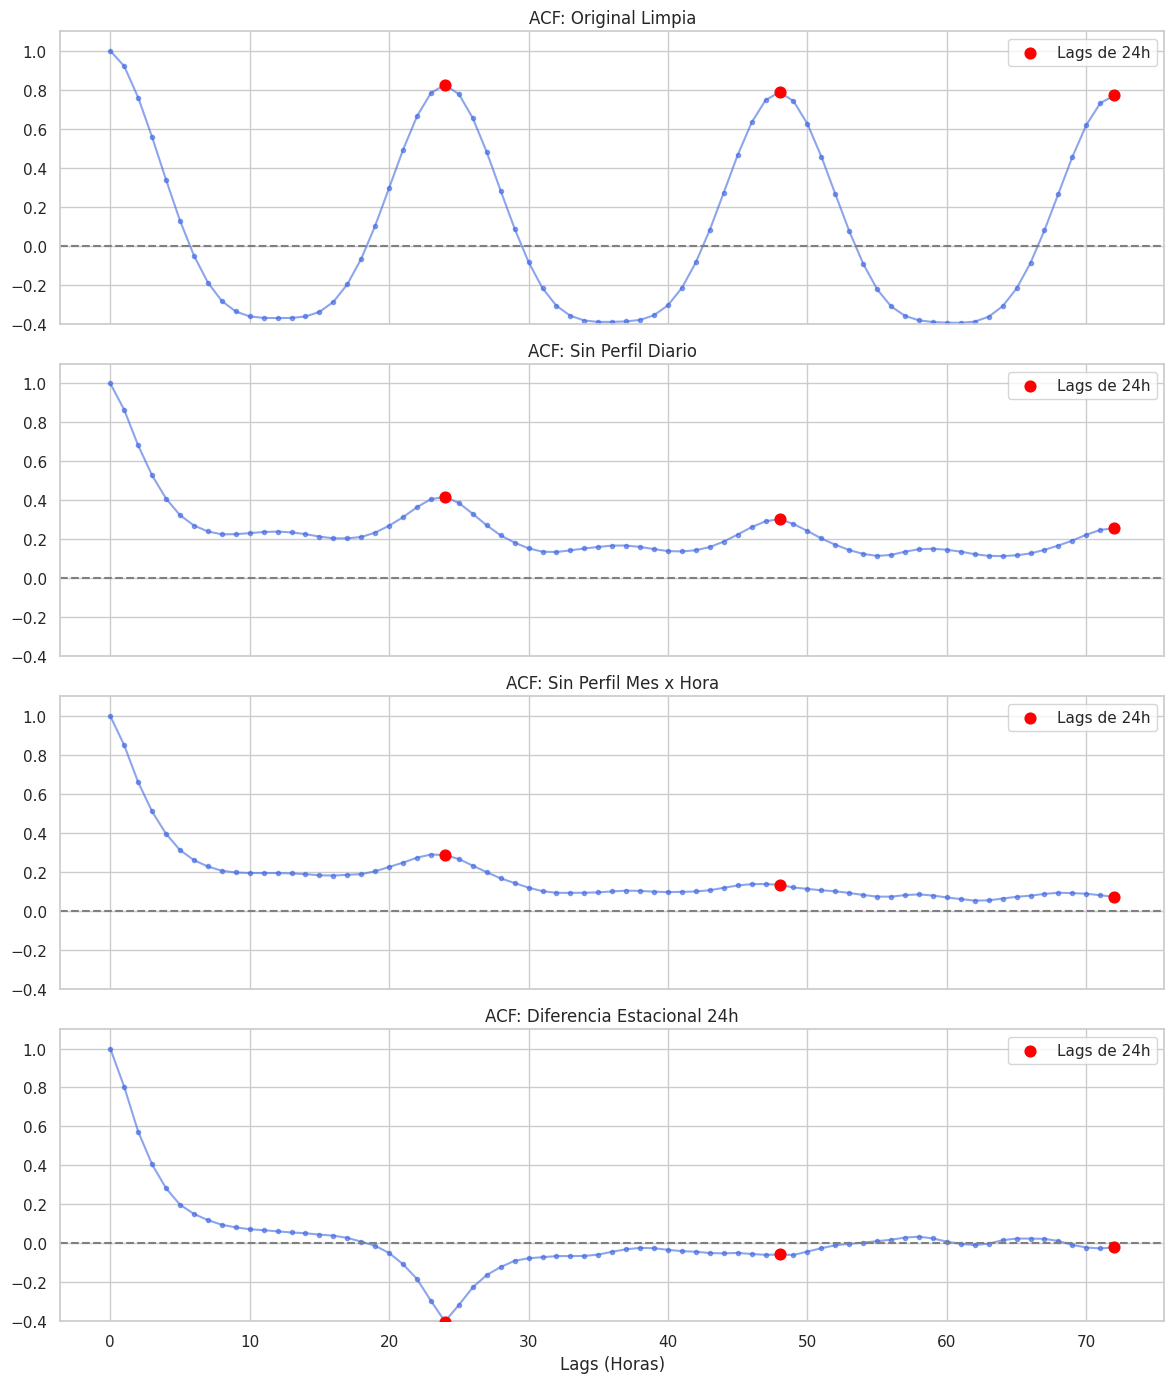

In [80]:
columnas = ['limpia', 'sin_perfil_diario', 'sin_perfil_mes_hora', 'dif_estacional_24h']
titulos = ['Original Limpia', 'Sin Perfil Diario', 'Sin Perfil Mes x Hora', 'Diferencia Estacional 24h']

fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)

for i, col in enumerate(columnas):
    serie_temp = serie_ozono[col].dropna()
    vals_acf = acf(serie_temp, nlags=72)
    lags = np.arange(len(vals_acf))

    # Graficar líneas del ACF
    axes[i].plot(lags, vals_acf, color='royalblue', marker='.', alpha=0.6)

    # Resaltar múltiplos de 24 horas
    lags_resaltar = [24, 48, 72]
    axes[i].scatter(lags_resaltar, vals_acf[lags_resaltar], color='red', s=60, zorder=5, label='Lags de 24h')

    axes[i].axhline(0, color='gray', linestyle='--')
    axes[i].set_title(f"ACF: {titulos[i]}")
    axes[i].set_ylim(-0.4, 1.1)
    axes[i].legend(loc='upper right')

plt.xlabel("Lags (Horas)")
plt.tight_layout()
plt.show()

## Resumen del Análisis de Estacionariedad

En este notebook hemos analizado el comportamiento de los niveles de Ozono (O3) para la estación **Pedregal (PED)** de forma secuencial y transparente, garantizando la consistencia del flujo sin recurrir a estructuras complejas.

---

### 6. Conclusiones Generales del Análisis de Estacionariedad

Al igual que en el análisis de referencia, las pruebas estadísticas y los correlogramas para la estación **Pedregal (PED)** nos permiten concluir lo siguiente:

* **Serie Original Saneada:** Aunque la prueba ADF indica rechazo de raíz unitaria debido a su fuerte ciclicidad diaria determinista, la prueba **KPSS** confirma categóricamente que la serie **no es estacionaria** ($p < 0.01$) debido a la oscilación sistemática de los niveles de ozono.
* **Remoción del Perfil Mes x Hora:** Al sustraer el perfil promedio por hora de cada mes, logramos estabilizar la media y reducir drásticamente la varianza. La prueba **KPSS** deja de rechazar la estacionariedad ($p > 0.10$), indicando que es el mejor método de estabilización determinista.
* **Diferenciación Estacional (diff 24h):** Es muy efectiva para remover la estacionalidad estocástica, logrando pasar de forma exitosa las pruebas de raíz unitaria. Sin embargo, introduce un efecto de **sobre-diferenciación** (*over-differencing*) reflejado en la fuerte correlación negativa en el lag de 24 horas del ACF.

---

*Fin del Reporte de Series de Tiempo - Estación PED 2026*